In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.model_selection import train_test_split

# 1. Load Data
filepath = 'Demand of last 2 years.xlsx'
df = pd.read_excel(filepath, sheet_name='demand_training_data')
prod_univ = pd.read_excel(filepath, sheet_name='Product_Universe')

# 2. Parse Dates
def parse_excel_date(val):
    if isinstance(val, (int, float)):
        return pd.to_datetime('1899-12-30') + pd.to_timedelta(val, unit='D')
    return pd.to_datetime(val)

for col in ['week_start_date', 'week_end_date', 'forecast_target_start', 'forecast_target_end']:
    df[col] = df[col].apply(parse_excel_date)

# 3. Merge Pricing Data & Format Unit Sizes
variants = []
for _, row in prod_univ.iterrows():
    for tier in range(1, 6):
        variants.append({
            'product_id': row['product_id'],
            'unit_size': row[f'unit_size_{tier}'],
            'base_cp_rs': float(row[f'cp_{tier}_rs']),
            'base_sp_rs': float(row[f'sp_{tier}_rs'])
        })
df = df.merge(pd.DataFrame(variants), on=['product_id', 'unit_size'], how='left')

def parse_unit(unit_str):
    parts = str(unit_str).strip().split()
    val = float(parts[0])
    if len(parts) > 1 and parts[1].lower() in ['l', 'kg']:
        val *= 1000.0
    return val

df['unit_quantity_std'] = df['unit_size'].apply(parse_unit)

# 4. Feature Engineering
df = df.sort_values(['week_number', 'location_id', 'demand_rank']).reset_index(drop=True)
df['festival_event'] = df['festival_event'].fillna('No_Festival')
df['weekend_share'] = df['weekend_units_sold'] / df['units_sold'].clip(lower=1)
df['weekday_to_weekend_ratio'] = df['weekday_units_sold'] / (df['weekend_units_sold'] + 1.0)
df['stockout_adjusted_units'] = df['units_sold'] * (1.0 + 0.12 * df['stockout_flag'])
df['effective_price_ratio'] = df['avg_selling_price_rs'] / df['base_sp_rs']
df['gross_margin_pct'] = (df['avg_selling_price_rs'] - df['base_cp_rs']) / df['avg_selling_price_rs']
df['temp_humidity_index'] = df['temperature_c'] * df['humidity_pct'] / 100.0
df['start_month'] = df['week_start_date'].dt.month
df['target_month'] = df['forecast_target_start'].dt.month
df['target_week_of_year'] = df['forecast_target_start'].dt.isocalendar().week.astype(int)
df['sin_week'] = np.sin(2 * np.pi * df['target_week_of_year'] / 52.0)
df['cos_week'] = np.cos(2 * np.pi * df['target_week_of_year'] / 52.0)

# Region/Product Aggregations
reg_stats = df.groupby(['location_id', 'week_number'])['units_sold'].agg(
    region_mean='mean', region_sum='sum'
).reset_index()
df = df.merge(reg_stats, on=['location_id', 'week_number'], how='left')
df['share_of_region'] = df['units_sold'] / df['region_sum']
df['ratio_to_region_mean'] = df['units_sold'] / df['region_mean']

# Historical Lags
df = df.sort_values(['location_id', 'product_id', 'week_number']).reset_index(drop=True)
grp = df.groupby(['location_id', 'product_id'])
df['lag1_units'] = grp['units_sold'].shift(1)
df['rolling3_mean'] = grp['units_sold'].transform(lambda s: s.shift(1).rolling(3, min_periods=1).mean())
df = df.sort_values(['week_number', 'location_id', 'demand_rank']).reset_index(drop=True)

# 5. Define Model Features
cat_features = ['location_id', 'region_of_kolkata', 'product_id', 'category_name', 'season', 'festival_event']
for col in cat_features:
    df[col] = df[col].astype('category')

num_features = [
    'demand_rank', 'unit_quantity_std', 'weekday_units_sold', 'weekend_units_sold', 'units_sold', 
    'weekend_share', 'weekday_to_weekend_ratio', 'stockout_adjusted_units', 'avg_selling_price_rs', 
    'effective_price_ratio', 'gross_margin_pct', 'promotion_flag', 'discount_pct', 'holiday_flag', 
    'temperature_c', 'rainfall_mm', 'temp_humidity_index', 'start_month', 'target_month', 
    'sin_week', 'cos_week', 'region_mean', 'share_of_region', 'ratio_to_region_mean', 
    'lag1_units', 'rolling3_mean'
]
features = cat_features + num_features
target = 'next_week_demand_target_units'
df['log_target_ratio'] = np.log(df[target] / df['units_sold'])

# 6. Train LightGBM (80/20 Split)
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=42, stratify=df['location_id'])
train_df = df.loc[train_idx]

model_dir = lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.03, max_depth=8, random_state=42, n_jobs=-1, verbose=-1)
model_dir.fit(train_df[features], train_df[target])

model_rat = lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.03, max_depth=8, random_state=42, n_jobs=-1, verbose=-1)
model_rat.fit(train_df[features], train_df['log_target_ratio'])

# 7. Generate Predictions for ALL 27,800 Rows
pred_dir = model_dir.predict(df[features])
pred_rat = df['units_sold'].values * np.exp(model_rat.predict(df[features]))
df['predicted_next_week_demand_units'] = np.round(0.5 * pred_dir + 0.5 * pred_rat).astype(int)

# 8. Format Final Output DataFrame
all_27800_predictions_df = df[[
    'demand_id', 'week_start_date', 'week_end_date', 'year', 'week_number',
    'location_id', 'region_of_kolkata', 'demand_rank', 'product_id', 'product_name',
    'category_name', 'brand', 'unit_size', 'units_sold', 'avg_selling_price_rs',
    'promotion_flag', 'discount_pct', 'holiday_flag', 'festival_event', 'season',
    'forecast_target_start', 'forecast_target_end', 
    'next_week_demand_target_units', 'predicted_next_week_demand_units'
]].copy()

all_27800_predictions_df['prediction_error_units'] = all_27800_predictions_df['predicted_next_week_demand_units'] - all_27800_predictions_df['next_week_demand_target_units']
all_27800_predictions_df['abs_error_units'] = all_27800_predictions_df['prediction_error_units'].abs()
all_27800_predictions_df['percentage_error_pct'] = (all_27800_predictions_df['abs_error_units'] / all_27800_predictions_df['next_week_demand_target_units'] * 100).round(2)

# Export to Excel
output_file = 'All_27800_Row_Predictions.xlsx'
all_27800_predictions_df.to_excel(output_file, index=False)
print(f"Successfully generated and saved all 27,800 predictions to '{output_file}'")

# Display the first 15 rows in the notebook
display(all_27800_predictions_df.head(15))

Successfully generated and saved all 27,800 predictions to 'All_27800_Row_Predictions.xlsx'


,demand_id,week_start_date,week_end_date,year,week_number,location_id,region_of_kolkata,demand_rank,product_id,product_name,...,holiday_flag,festival_event,season,forecast_target_start,forecast_target_end,next_week_demand_target_units,predicted_next_week_demand_units,prediction_error_units,abs_error_units,percentage_error_pct
0,DEM-0000001,2024-01-01,2024-01-07,2024,1,KOL-LOC-001,Lake Gardens,1,DAI-005,Mother Dairy Curd,...,0,No_Festival,Winter,2024-01-08,2024-01-14,152,150,-2,2,1.32
1,DEM-0000002,2024-01-01,2024-01-07,2024,1,KOL-LOC-001,Lake Gardens,2,TEA-009,Bru Instant Coffee,...,0,No_Festival,Winter,2024-01-08,2024-01-14,110,98,-12,12,10.91
2,DEM-0000003,2024-01-01,2024-01-07,2024,1,KOL-LOC-001,Lake Gardens,3,TEA-002,Tata Tea Premium,...,0,No_Festival,Winter,2024-01-08,2024-01-14,97,97,0,0,0.00
3,DEM-0000004,2024-01-01,2024-01-07,2024,1,KOL-LOC-001,Lake Gardens,4,BEV-007,Frooti Mango,...,0,No_Festival,Winter,2024-01-08,2024-01-14,84,86,2,2,2.38
4,DEM-0000005,2024-01-01,2024-01-07,2024,1,KOL-LOC-001,Lake Gardens,5,INS-008,Kellogg's Corn Flakes,...,0,No_Festival,Winter,2024-01-08,2024-01-14,72,84,12,12,16.67
5,DEM-0000006,2024-01-01,2024-01-07,2024,1,KOL-LOC-002,Jadavpur,1,TEA-004,Brooke Bond Taj Mahal,...,0,No_Festival,Winter,2024-01-08,2024-01-14,124,125,1,1,0.81
6,DEM-0000007,2024-01-01,2024-01-07,2024,1,KOL-LOC-002,Jadavpur,2,TEA-001,Tata Tea Gold,...,0,No_Festival,Winter,2024-01-08,2024-01-14,121,127,6,6,4.96
7,DEM-0000008,2024-01-01,2024-01-07,2024,1,KOL-LOC-002,Jadavpur,3,TEA-009,Bru Instant Coffee,...,0,No_Festival,Winter,2024-01-08,2024-01-14,121,124,3,3,2.48
8,DEM-0000009,2024-01-01,2024-01-07,2024,1,KOL-LOC-002,Jadavpur,4,TEA-002,Tata Tea Premium,...,0,No_Festival,Winter,2024-01-08,2024-01-14,133,125,-8,8,6.02
9,DEM-0000010,2024-01-01,2024-01-07,2024,1,KOL-LOC-002,Jadavpur,5,DAI-002,Amul Taaza Toned Milk,...,0,No_Festival,Winter,2024-01-08,2024-01-14,136,119,-17,17,12.50


In [2]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Extract the true and predicted values specifically for the 20% test set 
# (using the 'test_idx' generated in the previous code block)
test_results = all_27800_predictions_df.loc[test_idx]

y_true = test_results['next_week_demand_target_units']
y_pred = test_results['predicted_next_week_demand_units']

# 1. R-Squared (R²)
r2 = r2_score(y_true, y_pred)

# 2. Root Mean Squared Error (RMSE)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))

# 3. Mean Absolute Error (MAE)
mae = mean_absolute_error(y_true, y_pred)

# 4. Relative Mean Absolute Error (RMAE)
# Calculated as MAE divided by the mean of the actual target values
rmae = mae / y_true.mean()

# Print the results cleanly
print("=== MODEL EVALUATION METRICS (TEST SET) ===")
print(f"R² Score : {r2:.4f}")
print(f"RMSE     : {rmse:.2f} units")
print(f"MAE      : {mae:.2f} units")
print(f"RMAE     : {rmae:.4f} (or {rmae * 100:.2f}%)")

=== MODEL EVALUATION METRICS (TEST SET) ===
R² Score : 0.9526
RMSE     : 9.98 units
MAE      : 7.83 units
RMAE     : 0.0632 (or 6.32%)


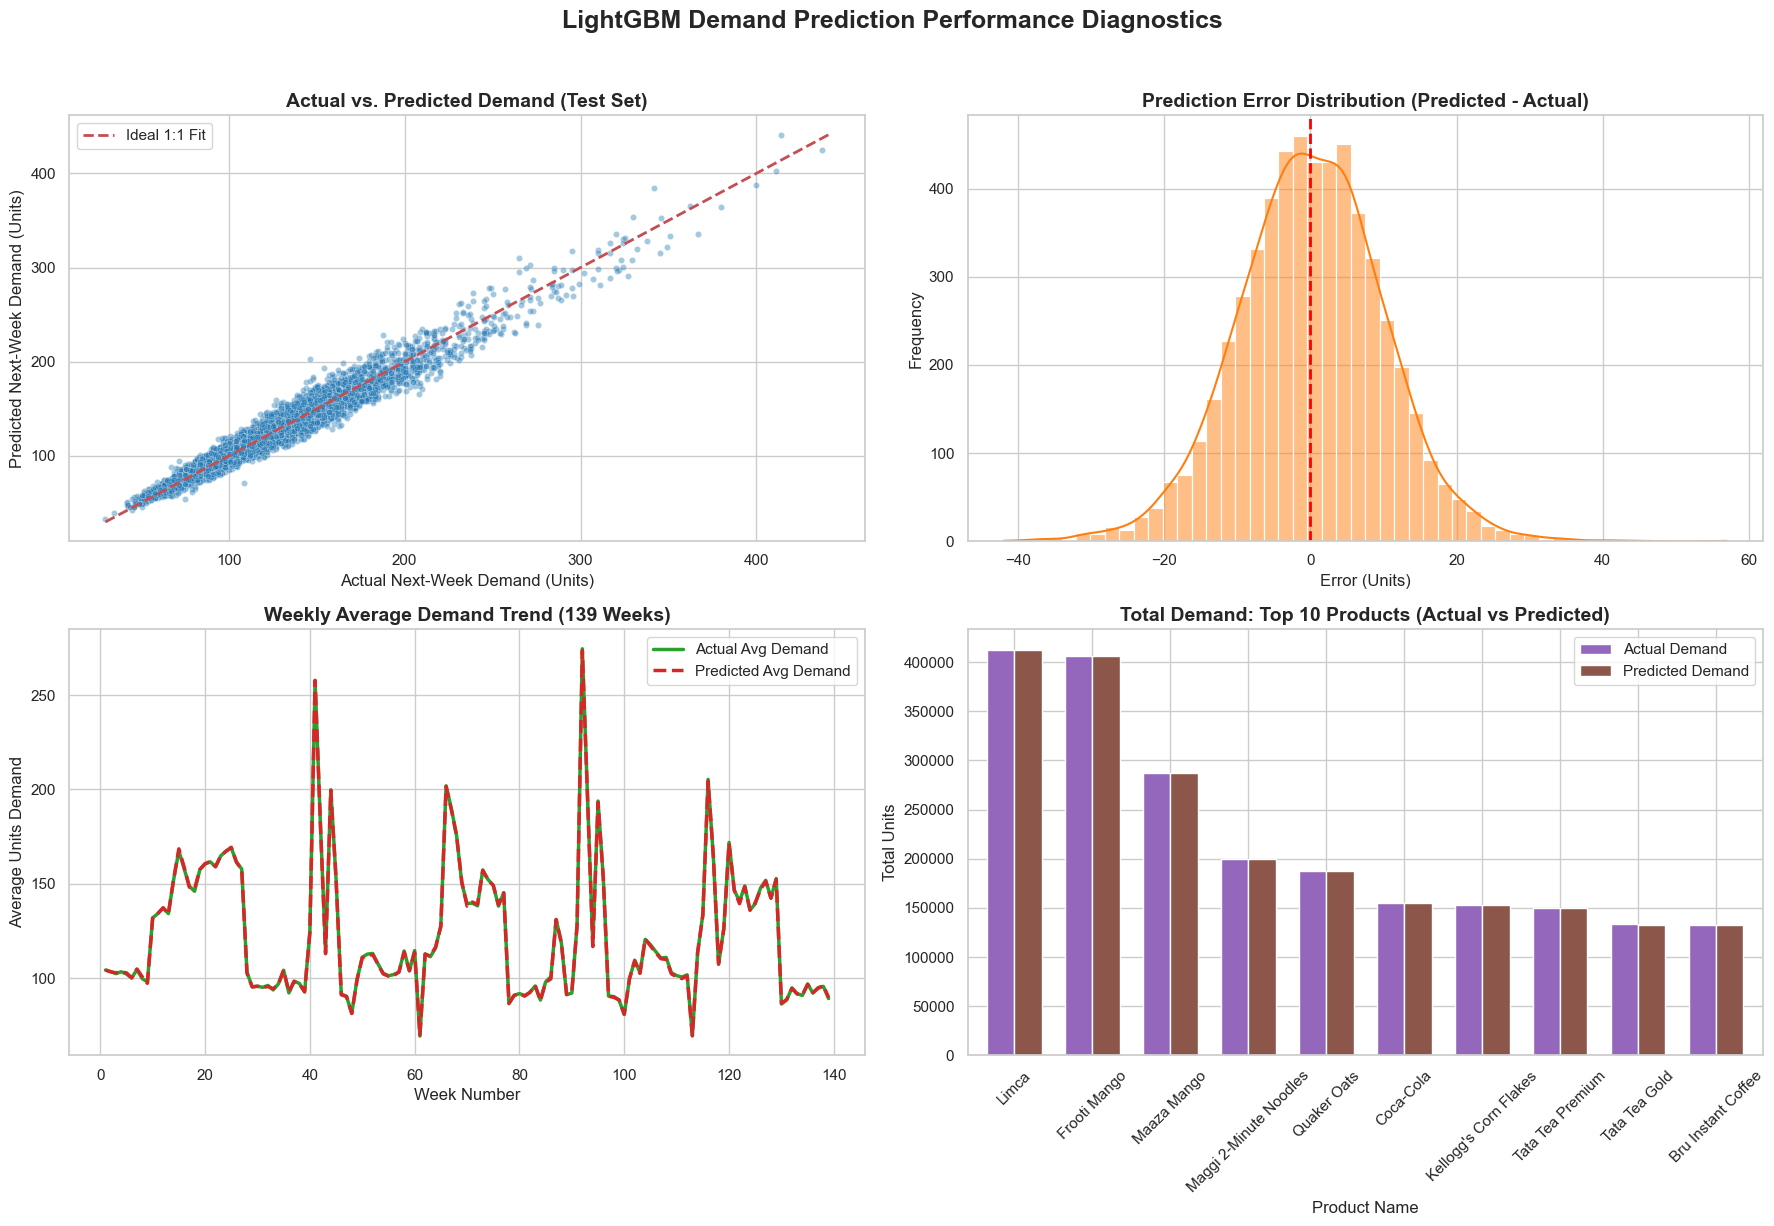

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set overall plotting style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle('LightGBM Demand Prediction Performance Diagnostics', fontsize=18, fontweight='bold', y=1.02)

# Extract test set for performance graphs
test_results = all_27800_predictions_df.loc[test_idx].copy()

# ---------------------------------------------------------
# 1. Actual vs Predicted Scatter Plot (Test Set)
# ---------------------------------------------------------
ax1 = axes[0, 0]
sns.scatterplot(
    data=test_results, 
    x='next_week_demand_target_units', 
    y='predicted_next_week_demand_units', 
    alpha=0.4, color='#1f77b4', s=20, ax=ax1
)
# Add ideal 1:1 fit line
min_val = min(test_results['next_week_demand_target_units'].min(), test_results['predicted_next_week_demand_units'].min())
max_val = max(test_results['next_week_demand_target_units'].max(), test_results['predicted_next_week_demand_units'].max())
ax1.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal 1:1 Fit')
ax1.set_title('Actual vs. Predicted Demand (Test Set)', fontsize=14, fontweight='bold')
ax1.set_xlabel('Actual Next-Week Demand (Units)', fontsize=12)
ax1.set_ylabel('Predicted Next-Week Demand (Units)', fontsize=12)
ax1.legend()

# ---------------------------------------------------------
# 2. Residuals / Error Distribution (Test Set)
# ---------------------------------------------------------
ax2 = axes[0, 1]
sns.histplot(test_results['prediction_error_units'], bins=50, kde=True, color='#ff7f0e', ax=ax2)
ax2.axvline(0, color='red', linestyle='--', lw=2)
ax2.set_title('Prediction Error Distribution (Predicted - Actual)', fontsize=14, fontweight='bold')
ax2.set_xlabel('Error (Units)', fontsize=12)
ax2.set_ylabel('Frequency', fontsize=12)

# ---------------------------------------------------------
# 3. Time Series: Average Weekly Demand (All Data)
# ---------------------------------------------------------
ax3 = axes[1, 0]
weekly_trend = all_27800_predictions_df.groupby('week_number')[['next_week_demand_target_units', 'predicted_next_week_demand_units']].mean().reset_index()
ax3.plot(weekly_trend['week_number'], weekly_trend['next_week_demand_target_units'], label='Actual Avg Demand', color='#2ca02c', lw=2.5)
ax3.plot(weekly_trend['week_number'], weekly_trend['predicted_next_week_demand_units'], label='Predicted Avg Demand', color='#d62728', linestyle='--', lw=2.5)
ax3.set_title('Weekly Average Demand Trend (139 Weeks)', fontsize=14, fontweight='bold')
ax3.set_xlabel('Week Number', fontsize=12)
ax3.set_ylabel('Average Units Demand', fontsize=12)
ax3.legend()

# ---------------------------------------------------------
# 4. Top 10 Products: Actual vs Predicted Volume
# ---------------------------------------------------------
ax4 = axes[1, 1]
top_products = all_27800_predictions_df.groupby('product_name')[['next_week_demand_target_units', 'predicted_next_week_demand_units']].sum().sort_values('next_week_demand_target_units', ascending=False).head(10)
top_products.plot(kind='bar', ax=ax4, color=['#9467bd', '#8c564b'], width=0.7)
ax4.set_title('Total Demand: Top 10 Products (Actual vs Predicted)', fontsize=14, fontweight='bold')
ax4.set_xlabel('Product Name', fontsize=12)
ax4.set_ylabel('Total Units', fontsize=12)
ax4.tick_params(axis='x', rotation=45)
ax4.legend(['Actual Demand', 'Predicted Demand'])

# Final layout adjustments
plt.tight_layout()
plt.show()